<i>École Polytechnique de Montréal</i>
<br>
<i>Cours PHS3104 : Mécanique quantique II</i>
<br>
<i>Session d'automne 2026</i>

<h3><center>Devoir 3 — Algorithme de Grover et coloriage de graphe</center></h3>

| Gabriel Poulin| Aiya Hamrouni | Alice Caron-Foisy |
|-------------------|-------------------|-------------------|
| 2379745 | 2364917| 2355748 |

In [11]:
%pip install qutip

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


**Initialisation du notebook**

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from qutip import Qobj, basis, tensor, qeye, expect
from qutip.measurement import measurement_statistics_povm
MAISON = {
    "couleurs": [("R", "V"), ("V", "B"), ("R", "B"),
                 ("V", "B"), ("R", "V")],
    "aretes": [(0, 1), (1, 2), (2, 3),
               (3, 0), (2, 4), (3, 4)]
}

TRIANGLE = {
    "couleurs": [("R", "V"), ("V", "B"), ("B", "R")],
    "aretes": [(0, 1), (1, 2), (2, 0)]
}

#### 4.1 Calculs analytiques [8 points]

**a) Phase et interférence — Pour le circuit de la figure 2a, avec $P(\phi) = \mathrm{diag}\left(1, e^{i\phi}\right)$, calculer l'état final et les probabilités de mesure après $P(\phi)H|0\rangle$, puis après $HP(\phi)H|0\rangle$. Montrer que la probabilité finale du résultat 1 vaut $\sin^2(\phi/2)$ et expliquer le rôle de la dernière porte de Hadamard.** [2 points]


Les opérateurs $H$ et $P(\phi)$ s'écrivent sous forme matricielle dans la base $\left\{|0\rangle,|1\rangle\right\}$:
$H = \frac{1}{\sqrt{2}}\begin{pmatrix}1&1\\1&-1\end{pmatrix},\quad P(\phi) = \begin{pmatrix}1&0\\0&e^{i\phi}\end{pmatrix}.$

En appliquant la porte Hadamard sur l'état $|0\rangle$:

$H|0\rangle= \frac{1}{\sqrt{2}}\begin{pmatrix}1&1\\1&-1\end{pmatrix}\begin{pmatrix}1\\0\end{pmatrix}=\frac{1}{\sqrt{2}}\begin{pmatrix}1\\1\end{pmatrix}$

Puis avec la phase relative $P(\phi)$:

$P(\phi)H|0\rangle= \frac{1}{\sqrt{2}}\begin{pmatrix}1&0\\0&e^{i\phi}\end{pmatrix}\begin{pmatrix}1\\1\end{pmatrix}=\frac{1}{\sqrt{2}}\begin{pmatrix}1\\e^{i\phi}\end{pmatrix}=\frac{1}{\sqrt{2}}\left(|0\rangle+e^{i\phi}|1\rangle\right)$

Les probabilités de mesurer 0 et 1 pour le système $P(\phi)H|0\rangle$ sont données par

$\mathcal{P}(0)=|\langle 0|P(\phi)H|0\rangle|^2=\left(\frac{1}{\sqrt{2}}\right)^2=\frac{1}{2},\quad\mathcal{P}(1)=|\langle 1|P(\phi)H|0\rangle|^2=\frac{|e^{i\phi}|^2}{2}=\frac{1}{2}$

Les probabilités des états sont indépendantes de $\phi$ malgré leur différence de phase.

En appliquant la porte Hadamard à nouveau sur le système:

$HP(\phi)H|0\rangle=\left(\frac{1}{\sqrt{2}}\right)^2\begin{pmatrix}1&1\\1&-1\end{pmatrix}\begin{pmatrix}1\\e^{i\phi}\end{pmatrix}=\frac{1}{2}\begin{pmatrix}1+e^{i\phi}\\1-e^{i\phi}\end{pmatrix}=\frac{1}{2}\left((1+e^{i\phi})|0\rangle+(1-e^{i\phi})|1\rangle\right)$

La probabilité de mesurer 1 s'écrit comme suit:

$\mathcal{P}(1)=|\langle1|HP(\phi)H|0\rangle|^2=|\frac{1}{2}\left(1-e^{i\phi}\right)|^2=\frac{1}{4}|1-e^{i\phi}|^2=\frac{1}{4}(1-e^{i\phi})(1-e^{-i\phi})=\frac{1}{4}\left(2-(e^{i\phi}+e^{-i\phi})\right)=\frac{1}{2}\left(1-\frac{e^{i\phi}+e^{-i\phi}}{2}\right)=\frac{1}{2}\left(1-\cos(\phi)\right)=\sin^2(\phi/2)$

$\mathcal{P}(0)=|\langle0|HP(\phi)H|0\rangle|^2=|\frac{1}{2}\left(1+e^{i\phi}\right)|^2=\frac{1}{4}|1+e^{i\phi}|^2=\frac{1}{2}(1+\cos(\phi))=\cos^2(\phi/2)$

L'état final peut être réécrit sachant que $1\pm e^{i\phi}=e^{i\phi/2}\alpha_\pm$ et $\alpha_+=2\cos(\phi/2),\quad \alpha_-=-2i\sin(\phi/2)$:

$HP(\phi)H|0\rangle=e^{i\phi/2}\left(\cos(\phi/2)|0\rangle-i\sin(\phi/2)|1\rangle\right)$

La première porte de Hadamard prépare une superposition à poids égaux des états $|0\rangle$ et $|1\rangle$ du qubit. Lorsque le système acquiert une phase relative grâce à $P(\phi)$, les probabilités de mesure demeurent inchangées, puisque celles-ci dépendent uniquement du module des amplitudes et non de leur phase. La deuxième porte de Hadamard permet alors de recombiner les amplitudes des deux états, de sorte que chaque amplitude finale résulte de l'addition ou de la soustraction de deux contributions, soit $(1+e^{i\phi})$ pour $|0\rangle$ et $(1-e^{i\phi})$ pour $|1\rangle$. Selon la valeur de $\phi$, ces contributions interfèrent de manière constructive ou destructive. Il est donc question de transformer une différence de phase, initialement sans effet sur les probabilités de mesure, en une différence de module entre les amplitudes des états, rendant ainsi leurs probabilités dépendantes de $\phi$.


**b) Action de la diffusion — Pour $|\psi\rangle = \sum_x a_x |x\rangle$, montrer que $D$ transforme chaque amplitude $a_x$ en $2\mu - a_x$, où $\mu = N^{-1}\sum_x a_x$.** [2 points]


L'état de superposition uniforme $|s\rangle$ et un état quelconque $|\psi\rangle$ s'écrivent dans la base computationnelle comme suit:

$|s\rangle=\frac{1}{\sqrt{N}}\sum_{x=0}^{N-1}|x\rangle,\qquad |\psi\rangle=\sum_{x=0}^{N-1}a_x|x\rangle$

L'opérateur de diffusion de Grover est défini par:

$D=2|s\rangle\langle s|-I_N$

où $I_N$ est la matrice identité de dimension $N$, dont les éléments sont donnés par:

$[I_N]_{xx'}=\langle x|I_N|x'\rangle=\delta_{xx'}=\begin{cases}1 & \text{si } x=x'\\0 & \text{sinon}\end{cases}$

On définit également la moyenne des amplitudes de l'état $|\psi\rangle$ par:

$\mu=\frac{1}{N}\sum_{x=0}^{N-1}a_x$

Pour déterminer l'action de l'opérateur de diffusion sur $|\psi\rangle$, on calcule d'abord  $\langle s|\psi\rangle$:

$\begin{aligned}\langle s|\psi\rangle&=\frac{1}{\sqrt{N}}\sum_{x'}\langle x'|\sum_x a_x|x\rangle\\&=\frac{1}{\sqrt{N}}\sum_{x'}\sum_x a_x\langle x'|x\rangle\\&=\frac{1}{\sqrt{N}}\sum_{x'}\sum_x a_x\delta_{x'x}\\&=\frac{1}{\sqrt{N}}\sum_x a_x\\&=\sqrt{N}\mu\end{aligned}$

En multipliant ce résultat par l'état $|s\rangle$, on obtient:

$\begin{aligned}|s\rangle\langle s|\psi\rangle&=\left(\frac{1}{\sqrt{N}}\sum_{x'}|x'\rangle\right)\left(\frac{1}{\sqrt{N}}\sum_x a_x\right)\\&=\frac{1}{N}\left(\sum_x a_x\right)\sum_{x'}|x'\rangle\\&=\mu\sum_{x'}|x'\rangle\end{aligned}$

En substituant cette expression dans la définition de l'opérateur de diffusion:

$\begin{aligned}D|\psi\rangle&=\left(2|s\rangle\langle s|-I_N\right)|\psi\rangle\\&=2|s\rangle\langle s|\psi\rangle-I_N|\psi\rangle\\&=2\mu\sum_x|x\rangle-\sum_x a_x|x\rangle\\&=\sum_x(2\mu-a_x)|x\rangle\end{aligned}$

On obtient donc:

$\boxed{D|\psi\rangle=\sum_x(2\mu-a_x)|x\rangle},\qquad\mu=\frac{1}{N}\sum_x a_x$

Ainsi, on constate que chaque amplitude est transformée selon $a_x\to 2\mu-a_x$. 


**c) Une itération à la main [4 points]**  
**1. Pour le triangle, identifier les chaînes valides et calculer les huit amplitudes après l'oracle, à partir de la superposition uniforme.**


Pour le triangle, une chaîne $abc$ représente une configuration de couleurs des trois sommets $A$, $B$ et $C$. Une configuration est valide si aucun sommet adjacent ne possède la même couleur. Le tableau suivant présente les huit configurations possibles, les conflits éventuels et les amplitudes obtenues après l'application de l'oracle.

| Chaîne $abc$ | A | B | C | Arête(s) en conflit | Valide ? | Amplitude après l'oracle |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| 000 | R | V | B | – | OUI | $-1/\sqrt{8}$ |
| 001 | R | V | R | CA | NON | $1/\sqrt{8}$ |
| 010 | R | B | B | BC | NON | $1/\sqrt{8}$ |
| 011 | R | B | R | CA | NON | $1/\sqrt{8}$ |
| 100 | V | V | B | AB | NON | $1/\sqrt{8}$ |
| 101 | V | V | R | AB | NON | $1/\sqrt{8}$ |
| 110 | V | B | B | BC | NON | $1/\sqrt{8}$ |
| 111 | V | B | R | – | OUI | $-1/\sqrt{8}$ |

On identifie donc deux configurations valides, soit $000$ et $111$, ce qui donne $M=2$ solutions.

À partir de la superposition uniforme $|s\rangle=\frac{1}{\sqrt{8}}\sum_{x=0}^{7}|x\rangle$, chaque état possède initialement une amplitude de $\frac{1}{\sqrt{8}}=\frac{1}{2\sqrt{2}}$.

Après l'application de l'oracle, l'état du système s'écrit:

$O_f|s\rangle=\frac{1}{\sqrt{8}}(-|000\rangle+|001\rangle+|010\rangle+|011\rangle+|100\rangle+|101\rangle+|110\rangle-|111\rangle)$



**2. Calculer les amplitudes après une diffusion, donner le ket final et la probabilité totale de succès. Expliquer pourquoi les probabilités ne changent pas à l'étape de l'oracle.**


À la suite de l'application de l'oracle, les deux états valides possèdent une amplitude de $-1/\sqrt{8}$, tandis que les six autres états ont une amplitude de $1/\sqrt{8}$. La moyenne $\mu$ des amplitudes est donc:

$\mu=\frac{1}{N}\sum_x a_x=\frac{1}{8}\frac{-2+6}{\sqrt{8}}=\frac{4}{8\sqrt{8}}=\frac{1}{2\sqrt{8}}$

En appliquant l'opérateur de diffusion $D$, chaque amplitude est transformée selon $a_x\to 2\mu-a_x$.

Pour les deux états valides:

$2\mu-a_x=2\left(\frac{1}{2\sqrt{8}}\right)-\left(-\frac{1}{\sqrt{8}}\right)=\frac{1}{\sqrt{8}}+\frac{1}{\sqrt{8}}=\frac{2}{2\sqrt{2}}=\frac{1}{\sqrt{2}}$

Pour les six états non valides:

$2\mu-a_x=2\left(\frac{1}{2\sqrt{8}}\right)-\left(\frac{1}{\sqrt{8}}\right)=\frac{1}{\sqrt{8}}-\frac{1}{\sqrt{8}}=0$

L'état final du système après l'application de l'oracle et de l'opérateur de diffusion s'écrit:

$DO_f|s\rangle=\sum_x(2\mu-a_x)|x\rangle=\frac{1}{\sqrt{2}}(|000\rangle+|111\rangle)+0(|001\rangle+|010\rangle+|011\rangle+|100\rangle+|101\rangle+|110\rangle)=\frac{1}{\sqrt{2}}(|000\rangle+|111\rangle)$

La probabilité totale de succès correspond à la somme des probabilités de mesurer l'un des deux états valides:

$P_{\text{succès}}=\left|\frac{1}{\sqrt{2}}\right|^2+\left|\frac{1}{\sqrt{2}}\right|^2=\frac{1}{2}+\frac{1}{2}=1$

L'oracle seul ne modifie pas les probabilités de mesure, puisqu'il inverse uniquement le signe des amplitudes des états valides et que $|-a_x|^2=|a_x|^2$. C'est l'opérateur de diffusion qui permet ensuite d'amplifier les amplitudes de ces états par inversion autour de la moyenne, tout en annulant celles des états non valides. Après une seule itération de Grover, la probabilité de mesurer une configuration valide atteint donc 100 %.


#### 4.2 Construction des opérateurs avec QuTiP [15 points]

Vous devez créer les fonctions ci-dessous qui retourneront des `Qobj` sur les $n$ qubits, de taille $2^n \times 2^n$, avec `dims=[[2]*n, [2]*n]`.

**a) Projecteurs locaux [2 points]**  
**1. Écrire `projecteur_local(n, k, b)`, qui retourne le projecteur $Q_k(b)$ défini en 3.2.**

In [13]:
def projecteur_local(n,k,b):
    if k < 0 or k >= n:
        raise ValueError("Indice k invalide.")
    if b != 0 and b != 1: #b doit être 0 ou 1
        raise ValueError("b doit être égal à 0 ou 1.")
    facteurs = []
    for i in range(n):
        if i == k:
            facteurs.append(basis(2, b).proj())   
        else:
            facteurs.append(qeye(2))              
    return tensor(facteurs)

**2. Pour $n = 3$, illustrer son action sur un état de base conservé et un état annulé.**

In [14]:
n = 3
Q = projecteur_local(n, 1, 0) 

conserve= basis([2]*n, [0, 0, 1])     
annule= basis([2]*n, [0, 1, 1])  

print(Q.dims, Q.shape)
print((Q * conserve - conserve).norm())
print((Q * annule).norm())

[[2, 2, 2], [2, 2, 2]] (8, 8)
0.0
0.0


L'application du projecteur sur l'état conservé donne $Q_1(0)|001⟩ = |001⟩$. L'état est conservé et la norme de la différence est de 0.0.
Pour l'état annulé la norme de la projection est nulle. Donc la projection annule l'état si le bit $k$ ne vaut pas $b$.

**b) Contraintes et oracle [7 points]**

**1. Écrire `conflit(n, u, v, couleurs)`, qui retourne $C_{uv}$ à partir des listes de couleurs.** [2 points]

In [15]:
def conflit(n,u,v,couleurs):
    I = tensor([qeye(2) for _ in range(n)])
    C_uv = 0 * I
    for i in (0, 1):
        for j in (0, 1):

            if couleurs[u][i] == couleurs[v][j]:

                Q_u = projecteur_local(n, u, i)
                Q_v = projecteur_local(n, v, j)

                C_uv += Q_u * Q_v

    return C_uv

**2. Donner le projecteur obtenu pour AB de la maison comme exemple de vérification.** [1 point]

In [16]:
C = conflit(5, 0, 1, MAISON["couleurs"])
#print(C) 
print((C - projecteur_local(5, 0, 1) * projecteur_local(5, 1, 0)).norm())

0.0


En affichant le résultat de print((C - projecteur_local(5, 0, 1) * projecteur_local(5, 1, 0)).norm()), on calcule la norme de la différence entre cet opérateur de conflit et le produit des deux projecteurs locaux. Le fait d'obtenir une norme de $0.0$ confirme que l'opérateur de conflit correspond bienbà l'intersection des projecteurs de ces deux sous-systèmes.

**3. Écrire `oracle(graphe)`, qui assemble $\Pi_{\text{val}}$ à partir des arêtes et retourne $O_f = I_N - 2\Pi_{\text{val}}$ sans programmer la liste des solutions (il devrait fonctionner pour la maison et le triangle).** [2 points]

In [17]:

def oracle(graphe):
    couleurs = graphe["couleurs"]
    aretes = graphe["aretes"]
    n = len(couleurs)
    I = tensor([qeye(2) for i in range(n)])

    Pi_val = I

    for u, v in aretes:

        C_uv = conflit(n, u, v, couleurs)

        Pi_val = Pi_val * (I - C_uv)

    O_f = I - 2 * Pi_val

    return O_f
for nom, g in [("triangle", TRIANGLE), ("maison", MAISON)]:
    O = oracle(g)
    n = len(g["couleurs"])
    N = 2**n
    d = np.real(np.diag(O.full()))
    print(nom, O.dims, O.shape)
    print("  diagonal :", np.allclose(O.full(), np.diag(d)))
    print("  valeurs   :", np.unique(np.round(d, 10)))
    print("  nb de -1  :", int(np.sum(d < 0)))

triangle [[2, 2, 2], [2, 2, 2]] (8, 8)
  diagonal : True
  valeurs   : [-1.  1.]
  nb de -1  : 2
maison [[2, 2, 2, 2, 2], [2, 2, 2, 2, 2]] (32, 32)
  diagonal : True
  valeurs   : [-1.  1.]
  nb de -1  : 4


**4. Justifier le fait que $O_f$ soit unitaire. Vérifier numériquement cette unitarité ainsi que le signe reçu par chaque état de base du triangle en utilisant une vérification indépendante des couleurs.** [2 points]

Une matrice U est unitaire si $U^\dag  U = I$. Ici, l'oracle s'écrit sous la forme $O_f = I_N - 2 \Pi_\text{val}$, où $\Pi_{\text{val}}$ est un projecteur ($\Pi^\dag = \Pi$ et $\Pi^2 = \Pi$), car chaque contrainte est diagonale avec des 0 et des 1, et le produit de projecteurs qui commutent reste un projecteur. Par conséquent: $O_f^\dag  O_f = (I_N - 2 \Pi_\text{val})^2 = I_N - 4\Pi_\text{val} + 4  \Pi_\text{val}l^2 = I_N$. Finalement, l'oracle inverse simplement certains signes d'amplitudes sans modifier leurs modules, préservant ainsi les probabilités.

In [18]:
def coloriage_valide(bits, graphe):
    couleurs = graphe["couleurs"]
    for u, v in graphe["aretes"]:
        if couleurs[u][bits[u]] == couleurs[v][bits[v]]:
            return False
    return True

def triangle_valide_bits(bits):
    a, b, c = bits
    ok_AB = (a == 0 or b == 1)   # Vérifier que les couleurs sont pareils ou non
    ok_BC = (b == 0 or c == 1)   
    ok_CA = (c == 0 or a == 1)   
    return ok_AB and ok_BC and ok_CA

def verifier_oracle(graphe, test_valide, tol=1e-10):
    n = len(graphe["couleurs"])
    O_f = oracle(graphe)
    I = qeye([2] * n)

    # Unitarité
    erreur = (O_f.dag() * O_f - I).norm()
    print("Erreur d'unitarité :", erreur)
    assert erreur < tol

    # Signe de chaque état de base
    print("\nVérification des états de base :")
    for x in range(2**n):
        chaine = format(x, f"0{n}b")       
        bits = [int(c) for c in chaine]     
        ket = basis([2] * n, bits)
        valide = test_valide(bits)
        signe_attendu = -1 if valide else 1
        erreur_etat = (O_f * ket - signe_attendu * ket).norm()
        print(chaine, "| Valide :", valide, "| Signe :", signe_attendu,
              "| Erreur :", erreur_etat)
        assert erreur_etat < tol

verifier_oracle(TRIANGLE, triangle_valide_bits)
verifier_oracle(MAISON, lambda bits: coloriage_valide(bits, MAISON))

Erreur d'unitarité : 0.0

Vérification des états de base :
000 | Valide : True | Signe : -1 | Erreur : 0.0
001 | Valide : False | Signe : 1 | Erreur : 0.0
010 | Valide : False | Signe : 1 | Erreur : 0.0
011 | Valide : False | Signe : 1 | Erreur : 0.0
100 | Valide : False | Signe : 1 | Erreur : 0.0
101 | Valide : False | Signe : 1 | Erreur : 0.0
110 | Valide : False | Signe : 1 | Erreur : 0.0
111 | Valide : True | Signe : -1 | Erreur : 0.0
Erreur d'unitarité : 0.0

Vérification des états de base :
00000 | Valide : False | Signe : 1 | Erreur : 0.0
00001 | Valide : False | Signe : 1 | Erreur : 0.0
00010 | Valide : False | Signe : 1 | Erreur : 0.0
00011 | Valide : True | Signe : -1 | Erreur : 0.0
00100 | Valide : True | Signe : -1 | Erreur : 0.0
00101 | Valide : False | Signe : 1 | Erreur : 0.0
00110 | Valide : False | Signe : 1 | Erreur : 0.0
00111 | Valide : False | Signe : 1 | Erreur : 0.0
01000 | Valide : False | Signe : 1 | Erreur : 0.0
01001 | Valide : False | Signe : 1 | Erreur : 0.

**c) Diffusion et circuit complet [6 points]**

**1. Écrire `diffusion(n)` à partir de $H^{\otimes n}$ et du projecteur sur $|0^n\rangle$.** [2 points]

In [19]:

def diffusion(n):
    H = Qobj(np.array([[1, 1],[1, -1]]) / np.sqrt(2))
    H_n = tensor([H for _ in range(n)])
    zero = tensor([basis(2, 0) for _ in range(n)])
    P0 = zero * zero.dag()

    I = tensor([qeye(2) for _ in range(n)])

    D = H_n * (2 * P0 - I) * H_n

    return D

**2. Écrire `circuit(graphe, r)`, qui retourne $U_r = \left(DO_f\right)^r H^{\otimes n}$, sans mesure finale.** [2 points]

In [20]:

def circuit(graphe, r):
    n = len(graphe["couleurs"])
    if r < 0 or int(r) != r:
        raise ValueError("r doit être un entier positif.")
    H=Qobj(np.array([[1, 1],[1, -1]]) / np.sqrt(2))
    H_n =tensor([H for _ in range(n)])
    O_f = oracle(graphe)
    D = diffusion(n)
    U_r = (D * O_f) ** int(r) * H_n
    return U_r

**3. Pour le triangle, comparer l'état après une itération avec le résultat analytique.** [2 points]

In [21]:

def resultat_analytique(graphe, test_valide):
    n = len(graphe["couleurs"])
    N = 2**n
    valides = []

    for x in range(N):
        bits = [int(c) for c in format(x, f"0{n}b")]
        valides.append(test_valide(bits))
    M = sum(valides)
    amp_valide = (3*N - 4*M) / (N*np.sqrt(N))
    amp_invalide = (N - 4*M) / (N*np.sqrt(N))
    amplitudes = np.array([amp_valide if v else amp_invalide for v in valides])
    psi = Qobj(amplitudes.reshape(-1, 1),dims=[[2]*n, [1]*n])

    print("N =", N, "| M =", M)
    print("Amplitude valide :", amp_valide)
    print("Amplitude invalide :", amp_invalide)

    return psi

graphe = TRIANGLE
n = len(graphe["couleurs"])
U = circuit(graphe, 1)
zero = basis([2]*n, [0]*n)
psi_numerique =U * zero
psi_theorique =resultat_analytique(graphe, triangle_valide_bits)
erreur =(psi_numerique - psi_theorique).norm()
print("\nAmplitudes numériques :",
      psi_numerique.full().ravel(),)
print("Amplitudes analytiques :",
      psi_theorique.full().ravel(), )

print("Erreur :", erreur)


N = 8 | M = 2
Amplitude valide : 0.7071067811865475
Amplitude invalide : 0.0

Amplitudes numériques : [7.07106781e-01+0.j 5.31300993e-17+0.j 5.31300993e-17+0.j
 2.53745237e-17+0.j 2.53745237e-17+0.j 2.53745237e-17+0.j
 2.53745237e-17+0.j 7.07106781e-01+0.j]
Amplitudes analytiques : [0.70710678+0.j 0.        +0.j 0.        +0.j 0.        +0.j
 0.        +0.j 0.        +0.j 0.        +0.j 0.70710678+0.j]
Erreur : 6.345482907645175e-16


Pour un système de $N = 8$ états avec $M = 2$ solutions recherchées, l'analyse des amplitudes après une itération de Grover montre une amplitude valide de $0.7071$ et une amplitude nulle de $0.0$ pour les états invalides. La comparaison entre le vecteur d'amplitudes numériques et le vecteur analytique met en évidence une correspondance parfaite, avec une erreur de l'ordre de $6.35 \times 10^{-16}$. Cette infime différence, directement liée à la précision de l'arrondi machine, ce qui valide rigoureusement l'implémentation de l'algorithme par rapport au modèle théorique attendu pour le triangle.

#### 4.3 Étude numérique de l'amplification [17 points]

**a) Validation classique — Trouver les chaînes valides et les couleurs correspondantes à chaque sommet pour le graphe maison. Cette liste servira à valider l'oracle et les résultats.** [2 points]

In [22]:
graphe = MAISON
n = len(graphe["couleurs"])
couleurs = graphe["couleurs"]

valides_maison = []
lignes = []          

for x in range(2**n):
    chaine = format(x, f"0{n}b")
    bits = [int(c) for c in chaine]
    if not coloriage_valide(bits, graphe):
        continue
    cols = [couleurs[a][bits[a]] for a in range(n)]
    valides_maison.append(x)
    lignes.append((chaine, x, cols))

M_maison = len(valides_maison)
print(f"{'chaîne':^7} | {'x':>2} | A B C D E")
print("-" * 25)
for chaine, x, cols in lignes:
    print(f"{chaine:^7} | {x:>2} | {' '.join(cols)}")
print(f"\nM = {len(valides_maison)} chaînes valides sur N = {2**n}")

chaîne  |  x | A B C D E
-------------------------
 00011  |  3 | R V R B V
 00100  |  4 | R V B V R
 01011  | 11 | R B R B V
 11011  | 27 | V B R B V

M = 4 chaînes valides sur N = 32


**b) Interférences et amplification [15 points]**  
**1. Pour les deux graphes et $r = 0, 1, 2, 3, 4$, calculer $|\psi_r\rangle$ et tracer la probabilité totale de succès (la somme des probabilités pour les chaînes valides) en fonction de $r$. Comparer à la formule de l'encadré et identifier le point d'arrêt près du premier maximum.** [6 points]

Triangle : N = 8, M = 2, θ = 30.00°, point d'arrêt (formule) = 1, max numérique à r = 1
   r |   P_num |    P_th
   0 |  0.2500 |  0.2500
   1 |  1.0000 |  1.0000
   2 |  0.2500 |  0.2500
   3 |  0.2500 |  0.2500
   4 |  1.0000 |  1.0000
  écart max : 4.1e-15



Maison : N = 32, M = 4, θ = 20.70°, point d'arrêt (formule) = 2, max numérique à r = 2
   r |   P_num |    P_th
   0 |  0.1250 |  0.1250
   1 |  0.7812 |  0.7813
   2 |  0.9453 |  0.9453
   3 |  0.3301 |  0.3301
   4 |  0.0122 |  0.0122
  écart max : 3.2e-15



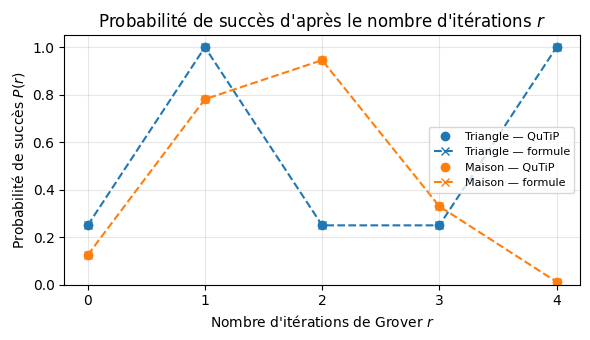

In [23]:
def bits_de(x, n):                                          
    return [int(c) for c in format(x, f"0{n}b")]

r_vals = np.arange(5)                                        
resultats = {}

for nom, graphe in [("Triangle", TRIANGLE), ("Maison", MAISON)]:
    n = len(graphe["couleurs"])
    N = 2 ** n
    valides = [x for x in range(N) if coloriage_valide(bits_de(x, n), graphe)]  
    M = len(valides)
    zero = basis([2] * n, [0] * n)                           

    P_num = []
    for r in r_vals:
        psi = circuit(graphe, r) * zero                      
        probs = np.abs(psi.full().ravel()) ** 2             
        P_num.append(probs[valides].sum())                   
    P_num = np.array(P_num)

    theta = np.arcsin(np.sqrt(M / N))
    P_th = np.sin((2 * r_vals + 1) * theta) ** 2
    r_stop = int(np.round(np.pi / (4 * theta) - 0.5))        
    r_max_num = np.argmax(P_num)

    resultats[nom] = (P_num, P_th, r_stop)
    print(f"{nom} : N = {N}, M = {M}, θ = {np.degrees(theta):.2f}°, "
          f"point d'arrêt (formule) = {r_stop}, max numérique à r = {r_max_num}")
    print(f"  {'r':>2} | {'P_num':>7} | {'P_th':>7}")
    for r in r_vals:
        print(f"  {r:>2} | {P_num[r]:>7.4f} | {P_th[r]:>7.4f}")
    print(f"  écart max : {np.abs(P_num - P_th).max():.1e}\n")

fig, ax = plt.subplots(figsize=(6, 3.5))
couleurs_graphes = {"Triangle": "tab:blue", "Maison": "tab:orange"}

for nom, (P_num, P_th, r_stop) in resultats.items():
    c = couleurs_graphes[nom]
    ax.plot(r_vals, P_num, "o", color=c, label=f"{nom} — QuTiP")
    ax.plot(r_vals, P_th, "x--", color=c, label=f"{nom} — formule")

ax.set_xlabel("Nombre d'itérations de Grover $r$")
ax.set_ylabel("Probabilité de succès $P(r)$")
ax.set_title("Probabilité de succès d'après le nombre d'itérations $r$")
ax.set_xticks(r_vals)
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Les tableaux et la figure montrent que les probabilités calculées avec QuTiP correspondent à la formule de l'encadré $P_{\text{sol}}(r) = \sin^2((2r+1)\theta)$, avec un écart maximal de l'ordre de $10^{-15}$, qui vient seulement de la précision numérique.

Pour le triangle, $M = 2$ et $N = 8$, donc $\theta = 30°$. La formule du point d'arrêt donne $\pi/(4\theta) - 1/2 = 1$ exactement et la probabilité de succès atteint 1 à $r = 1$, puisque $3\theta = 90°$. La probabilité redescend ensuite à 0,25, puis revient à 1 à $r = 4$, puisque $9\theta = 270°$.

Pour la maison, $M = 4$ et $N = 32$, donc $\theta \approx 20{,}7°$. La formule donne $\pi/(4\theta) - 1/2 \approx 1{,}67$, et l'entier le plus proche est $r = 2$. C'est le point d'arrêt choisi, et c'est aussi le maximum numérique, avec $P = 0{,}945$. La probabilité n'atteint pas 1 parce que $(2r+1)\theta$ ne tombe jamais exactement sur $90°$ pour un $r$ entier. Après $r = 2$, elle redescend (0,330 à $r = 3$, puis 0,012 à $r = 4$). Cela sera expliqué au 4.3 b) 3.

**2. Pour la maison, tracer l'histogramme des 32 probabilités au point d'arrêt choisi et identifier les chaînes valides sur ce graphique.** [3 points]

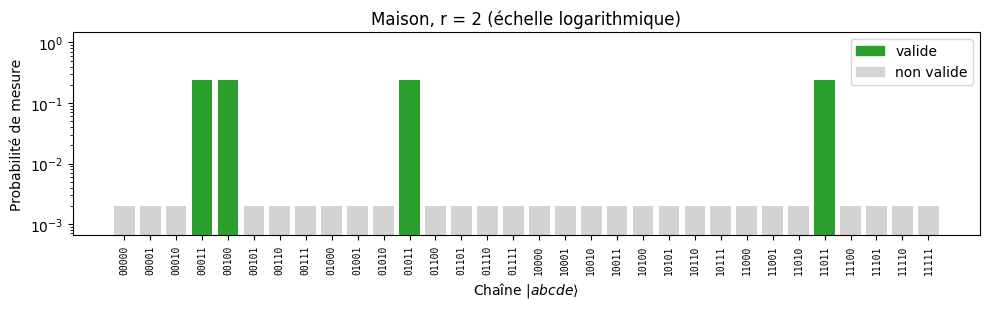

Somme des probabilités valides : 0.9453  (P_num au point d'arrêt : 0.9453)


In [24]:
nom = "Maison"
graphe = MAISON
n = len(graphe["couleurs"])
N = 2 ** n
P_num, P_th, r_stop = resultats[nom]
zero = basis([2] * n, [0] * n)

valides = [x for x in range(N) if coloriage_valide(bits_de(x, n), graphe)]
psi = circuit(graphe, r_stop) * zero                         
probs = np.abs(psi.full().ravel()) ** 2

etiquettes = [format(x, f"0{n}b") for x in range(N)]
couleurs_barres = ["tab:green" if x in valides else "lightgray" for x in range(N)]

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(range(N), probs, color=couleurs_barres)
ax.set_yscale("log")                                         
ax.set_ylim(bottom=max(probs.min() / 3, 1e-6), top=1.5)    
ax.set_xticks(range(N))
ax.set_xticklabels(etiquettes, rotation=90, fontsize=7, family="monospace")   
ax.set_xlabel(r"Chaîne $|abcde\rangle$")
ax.set_ylabel("Probabilité de mesure")
ax.set_title(f"Maison, r = {r_stop} (échelle logarithmique)")

from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="tab:green", label="valide"),
                   Patch(color="lightgray", label="non valide")])
plt.tight_layout()
plt.show()

print(f"Somme des probabilités valides : {probs[valides].sum():.4f}  "
      f"(P_num au point d'arrêt : {P_num[r_stop]:.4f})")

On voit sur la figure (en échelle logarithmique pour mettre en évidence les petites probabilités) que les états valides sont 00011, 00100, 01011 et 11011, comme déterminé au 4.3a). Il reste par contre des probabilités résiduelles pour les états non valides, car comme expliqué au 4.3b)1, aucun $r$ entier (donc aucun nombre d'itérations) ne donne une probabilité totale de 1 pour les états valides.

**3. Expliquer brièvement comment l'oracle puis la diffusion produisent l'amplification, pourquoi les probabilités ne changent pas immédiatement après l'oracle et pourquoi un plus grand nombre d'itérations n'est pas toujours préférable.** [6 points]

On note |bon> la superposition uniforme des chaînes valides et |mauvais> celle des chaînes non valides. Ces deux états sont perpendiculaires (orthogonaux), puisqu'ils n'ont aucune chaîne en commun, et ils forment donc les deux axes d'un plan. L'oracle $O_f$ multiplie l'amplitude des chaînes valides par $-1$ et laisse les autres intactes. Dans ce plan, l'état |s> est proche de l'axe mauvais parce qu'il y a beaucoup plus de chaînes non valides que de valides ($\sin\theta = \sqrt{M/N}$, soit $\theta \approx 20{,}7°$ pour la maison). $O_f$ fait une réflexion par rapport à l'axe mauvais (l'état passe de $\theta$ à $-\theta$), puis $D$ fait une réflexion par rapport à |s> (il passe de $-\theta$ à $3\theta$). Ensemble, ces deux réflexions font tourner l'état de $2\theta$ vers l'axe bon à chaque itération. Vu sur les amplitudes, $D$ fait $a_x \mapsto 2\mu - a_x$ : les amplitudes négatives des chaînes valides deviennent grandes et positives.

Les probabilités ne changent pas après l'oracle, puisque changer le signe d'une amplitude ne change pas son module carré. L'information est dans la phase, et c'est la diffusion qui la transforme en probabilité.

Après $r$ itérations, l'état est à l'angle $(2r+1)\theta$ (d'après la formule de l'énoncé). Si on itère trop, on dépasse l'axe bon et la probabilité redescend. Pour la maison, elle passe de $0{,}945$ à $r=2$ à $0{,}330$ à $r=3$, puis à $0{,}012$ à $r=4$. La figure suivante montre l'effet de $O_f$ et $D$ pour le graphe de maison. 

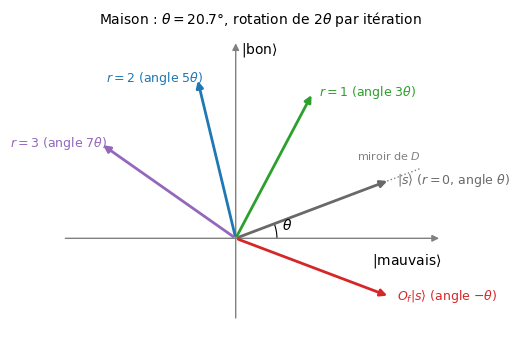

In [25]:
N_maison = 2 ** len(MAISON["couleurs"])
theta = np.arcsin(np.sqrt(M_maison / N_maison))

def fleche(ax, angle, couleur, texte, decal=(0.04, 0.0)):
    x, y = np.cos(angle), np.sin(angle)
    ax.annotate("", xy=(x, y), xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", color=couleur, lw=2))
    ax.text(x + decal[0], y + decal[1], texte, color=couleur, fontsize=9,
            ha="left" if x >= 0 else "right", va="center")

fig, ax = plt.subplots(figsize=(5.5, 4.2))
ax.annotate("", xy=(1.25, 0), xytext=(-1.05, 0), arrowprops=dict(arrowstyle="-|>", color="gray"))
ax.annotate("", xy=(0, 1.2), xytext=(0, -0.5), arrowprops=dict(arrowstyle="-|>", color="gray"))
ax.text(1.25, -0.08, r"$|\mathrm{mauvais}\rangle$", ha="right", va="top", fontsize=10)
ax.text(0.03, 1.2, r"$|\mathrm{bon}\rangle$", va="top", fontsize=10)

ax.plot([0, 1.2*np.cos(theta)], [0, 1.2*np.sin(theta)], ls=":", color="gray", lw=1)
ax.text(1.2*np.cos(theta), 1.2*np.sin(theta) + 0.05, r"miroir de $D$",
        color="gray", fontsize=8, ha="right")

fleche(ax, theta,   "dimgray",    r"$|s\rangle$ ($r=0$, angle $\theta$)")
fleche(ax, -theta,  "tab:red",    r"$O_f|s\rangle$ (angle $-\theta$)")
fleche(ax, 3*theta, "tab:green",  r"$r=1$ (angle $3\theta$)")
fleche(ax, 5*theta, "tab:blue",   r"$r=2$ (angle $5\theta$)")
fleche(ax, 7*theta, "tab:purple", r"$r=3$ (angle $7\theta$)")

arc = np.linspace(0, theta, 30)
ax.plot(0.25*np.cos(arc), 0.25*np.sin(arc), color="k", lw=0.8)
ax.text(0.28, 0.05, r"$\theta$", fontsize=10)

ax.set_title(rf"Maison : $\theta = {np.degrees(theta):.1f}°$, rotation de $2\theta$ par itération",
             fontsize=10)
ax.set_xlim(-1.3, 1.6)
ax.set_ylim(-0.55, 1.25)
ax.set_aspect("equal")
ax.axis("off")
plt.tight_layout()
plt.show()